In [1]:
# # Lab 7 | Transfer Learning Swin Transformer (Swin-T) trên CIFAR-100
# **Chạy trên Kaggle GPU.** Cấu trúc giữ theo bài `07_assessment.ipynb` của giảng viên: 7.1 Dataset → 7.2 Pretrained → 7.3 Freeze → 7.4 Head → 7.5 Loss/Optimizer → 7.6 Transforms → 7.7 DataLoader → 7.8 Train head → 7.9 Unfreeze/Fine-tune → 7.10 Validate → 7.11 Final assessment trên TEST. 
#
# **Quy tắc đánh giá:** Chỉ dùng train để cập nhật trọng số; validation để chọn checkpoint tốt nhất; test dùng **một lần ở cuối** sau khi chốt cấu hình. `best` có nghĩa là checkpoint tốt nhất theo **Validation Accuracy**, không phải mô hình có Train Accuracy cao nhất. Không dùng early stopping ở bản này. Những số liệu in ra là kết quả thật của phiên Kaggle của bạn.
print('Notebook Lab 7 Swin-T: các đoạn thuyết minh đã chuyển thành comment Python.')
print('Thực hiện lần lượt từ trên xuống; cuối notebook sẽ lưu checkpoint, biểu đồ và ZIP.')

Notebook Lab 7 Swin-T: các đoạn thuyết minh đã chuyển thành comment Python.
Thực hiện lần lượt từ trên xuống; cuối notebook sẽ lưu checkpoint, biểu đồ và ZIP.


In [2]:
# 0. CẤU HÌNH VÀ THƯ VIỆN — bật Kaggle GPU và Internet khi tải dữ liệu/weights lần đầu
import os, random, time, json, copy, shutil, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import swin_t, Swin_T_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from tqdm.auto import tqdm

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| Torch:', torch.__version__)
if DEVICE.type != 'cuda': print('CẢNH BÁO: chưa bật GPU, train sẽ rất chậm.')

N_CLASSES=100
IMAGE_SIZE=224
BATCH_SIZE=16
NUM_WORKERS=0  # Kaggle/Jupyter: tránh lỗi multiprocessing DataLoader
HEAD_EPOCHS=3
FINE_TUNE_EPOCHS=8
HEAD_LR=1e-3
BACKBONE_LR=1e-5
FINETUNE_HEAD_LR=1e-4
WEIGHT_DECAY=0.05
RUN_FINAL_TEST=True  # Chỉ để True KHI đã chốt mô hình, không dùng Test để chỉnh siêu tham số
DATA_DIR=Path('/kaggle/working/cifar100_data')
OUTPUT_DIR=Path('/kaggle/working/lab7_swin_cifar100_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Device: cuda | Torch: 2.11.0+cu128


In [3]:
# ## 7.1 The Dataset — CIFAR-100
# CIFAR-100 có 100 lớp: 50.000 ảnh train gốc và 10.000 ảnh test gốc. Tách tập train gốc theo stratified: **45.000 train + 5.000 validation**; giữ riêng 10.000 test. Mỗi ảnh gốc RGB kích thước 32×32, resize lên 224×224 để phù hợp Swin-T pretrained. Resize **không tạo thêm chi tiết ảnh**.

In [4]:
# ## 7.2 Load ImageNet Base Model
# Thay VGG16 của lab bằng `swin_t` từ TorchVision và weights `IMAGENET1K_V1`. Swin-T pretrained đã có head gốc 1.000 lớp; ta thay head tại bước 7.4.

In [5]:
# 7.2 — TẢI MÔ HÌNH CÓ SẴN VÀ TRỌNG SỐ PRETRAINED
weights = Swin_T_Weights.IMAGENET1K_V1
my_model = swin_t(weights=weights)
original_head_in = my_model.head.in_features  # Swin-T: 768
print('Head gốc:', original_head_in, '->', my_model.head.out_features)


Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 182MB/s]  


Head gốc: 768 -> 1000


In [6]:
# ## 7.3 Freeze Base Model
# Đóng băng toàn bộ tham số pretrained trước khi tạo head mới. Mục tiêu giai đoạn đầu: không làm thay đổi kiến thức đã học từ ImageNet.

In [7]:
# 7.3 — KHÔNG CẬP NHẬT BACKBONE TRONG GIAI ĐOẠN 1
my_model.requires_grad_(False)
print('Backbone frozen:', not any(p.requires_grad for p in my_model.parameters()))


Backbone frozen: True


In [8]:
# ## 7.4 Add Layers to Model
# Thay classifier gốc bằng `Linear(768,100)`. Sau khi thay, chỉ head mới có `requires_grad=True`; số tham số head = 768×100 + 100 bias = **76.900**.

In [9]:
# 7.4 — THÊM HEAD 100 LỚP CHO CIFAR-100
my_model.head=nn.Linear(original_head_in, N_CLASSES)
my_model=my_model.to(DEVICE)
def param_count(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if (p.requires_grad or not trainable_only))
print('Head:', my_model.head)
print('Tổng tham số:', f'{param_count(my_model):,}')
print('Tham số học giai đoạn 1:', f'{param_count(my_model,True):,}')
assert my_model.head.out_features == N_CLASSES
assert param_count(my_model,True)==original_head_in*N_CLASSES+N_CLASSES


Head: Linear(in_features=768, out_features=100, bias=True)
Tổng tham số: 27,596,254
Tham số học giai đoạn 1: 76,900


In [10]:
# ## 7.5 Compile Model — Loss và Optimizer
# PyTorch không bắt buộc `compile`. Lab 7 dùng Adam; bản này dùng **AdamW** và CrossEntropyLoss, phù hợp phân loại 100 lớp. Head học nhanh hơn backbone sau khi unfreeze. GPU sử dụng AMP để giảm VRAM.

In [11]:
# 7.5 — LOSS, OPTIMIZER, MIXED PRECISION
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(filter(lambda p:p.requires_grad, my_model.parameters()), lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
scaler=torch.amp.GradScaler('cuda', enabled=DEVICE.type=='cuda')


In [12]:
# ## 7.6 Data Transforms
# Train có RandomCrop/RandomHorizontalFlip; Validation/Test chỉ resize, tensor và normalize. Các tham số normalize theo ImageNet để tương thích pretrained weights.

In [13]:
# 7.6 — PREPROCESSING VÀ AUGMENTATION
mean=(0.485,0.456,0.406)
std=(0.229,0.224,0.225)
train_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.RandomCrop(IMAGE_SIZE, padding=12, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])
valid_test_transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])


In [14]:
# ## 7.7 Load Dataset
# Tách stratified giữ tỷ lệ 100 lớp; **Test hoàn toàn độc lập**, không sử dụng trong optimizer hoặc chọn best checkpoint.

In [15]:
# 7.7 — DOWNLOAD, CHIA TẬP VÀ DATALOADER
train_aug=datasets.CIFAR100(root=str(DATA_DIR), train=True, download=True, transform=train_transform)
train_eval=datasets.CIFAR100(root=str(DATA_DIR), train=True, download=False, transform=valid_test_transform)
test_ds=datasets.CIFAR100(root=str(DATA_DIR), train=False, download=True, transform=valid_test_transform)
train_idx,val_idx=train_test_split(
    np.arange(len(train_aug)), test_size=.1, random_state=SEED,
    stratify=np.asarray(train_aug.targets)
)
assert len(set(train_idx).intersection(set(val_idx)))==0
train_ds=Subset(train_aug,train_idx)
val_ds=Subset(train_eval,val_idx)
kwargs=dict(batch_size=BATCH_SIZE,num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda')
train_loader=DataLoader(train_ds,shuffle=True,**kwargs)
val_loader=DataLoader(val_ds,shuffle=False,**kwargs)
test_loader=DataLoader(test_ds,shuffle=False,**kwargs)
class_names=train_aug.classes
print('Train:',len(train_ds),'Validation:',len(val_ds),'Test:',len(test_ds))
# Xuất danh sách chỉ số chia để tái lập và so sánh CNN
np.savez(OUTPUT_DIR/'split_indices.npz',train_idx=train_idx,val_idx=val_idx)


100%|██████████| 169M/169M [18:05<00:00, 156kB/s] 


Train: 45000 Validation: 5000 Test: 10000


In [16]:
# ## 7.8 Train the Model — chỉ huấn luyện head (3 epoch)
# Huấn luyện classifier khi backbone đang freeze. Sau mỗi epoch: train/validation loss, accuracy, thời gian; lưu **best head** theo validation accuracy và loss. `best_head` là kết quả trung gian, chưa phải mô hình sau fine-tuning.

In [17]:
# 7.8 — HÀM HUẤN LUYỆN / VALIDATION VÀ QUẢN LÝ BEST CHECKPOINT
history=[]
checkpoint_info={}

def one_epoch(loader, optimizer=None, label=''):
    training=optimizer is not None
    my_model.train(training)
    total_loss,correct,total=0.,0,0
    for x,y in tqdm(loader,desc=label,leave=False,mininterval=10):
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type='cuda',enabled=DEVICE.type=='cuda'):
                logits=my_model(x)
                loss=loss_function(logits,y)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss+=float(loss.item())*y.size(0)
        correct+=int((logits.argmax(1)==y).sum().item())
        total+=y.size(0)
    return total_loss/total,correct/total

def save_checkpoint(path,phase,epoch,val_loss,val_acc):
    torch.save({
        'model_state_dict':my_model.state_dict(),
        'phase':phase,'epoch':epoch,
        'val_loss':float(val_loss),'val_acc':float(val_acc),
        'arch':'swin_t','n_classes':N_CLASSES,
        'pretrained_weights':'IMAGENET1K_V1'
    },path)

def run_stage(phase,epochs,optimizer,scheduler=None):
    # Mỗi giai đoạn có best riêng để không lẫn checkpoint head và fine-tune
    best_acc=-1.;best_loss=float('inf')
    for epoch in range(1,epochs+1):
        t0=time.time()
        train_loss,train_acc=one_epoch(train_loader,optimizer,f'{phase} E{epoch}/{epochs} TRAIN')
        val_loss,val_acc=one_epoch(val_loader,None,f'{phase} E{epoch}/{epochs} VAL')
        if scheduler is not None:scheduler.step()
        record=dict(phase=phase,epoch_in_phase=epoch,global_epoch=len(history)+1,
                    train_loss=train_loss,train_acc=train_acc,val_loss=val_loss,val_acc=val_acc,
                    seconds=time.time()-t0)
        history.append(record)
        print(f'{phase} {epoch}/{epochs}: train loss={train_loss:.4f}, acc={train_acc:.2%} | '
              f'val loss={val_loss:.4f}, acc={val_acc:.2%} | {record["seconds"]:.0f}s',flush=True)
        if val_acc>best_acc:
            best_acc=val_acc
            path=OUTPUT_DIR/f'best_{phase}_by_acc.pth'
            save_checkpoint(path,phase,epoch,val_loss,val_acc)
            print('  Saved BEST ACC:',path.name)
        if val_loss<best_loss:
            best_loss=val_loss
            path=OUTPUT_DIR/f'best_{phase}_by_loss.pth'
            save_checkpoint(path,phase,epoch,val_loss,val_acc)
            print('  Saved BEST LOSS:',path.name)
        pd.DataFrame(history).to_csv(OUTPUT_DIR/'training_history.csv',index=False)
    checkpoint_info[phase]=dict(best_val_acc=best_acc,best_val_loss=best_loss)
    print(f'HOÀN THÀNH {phase}: best validation accuracy={best_acc:.2%}; best validation loss={best_loss:.4f}',flush=True)

run_stage('head',HEAD_EPOCHS,optimizer)


head E1/3 TRAIN:   0%|          | 0/2813 [00:00<?, ?it/s]

head E1/3 VAL:   0%|          | 0/313 [00:00<?, ?it/s]

head 1/3: train loss=1.3330, acc=64.54% | val loss=0.8567, acc=74.58% | 188s
  Saved BEST ACC: best_head_by_acc.pth
  Saved BEST LOSS: best_head_by_loss.pth


head E2/3 TRAIN:   0%|          | 0/2813 [00:00<?, ?it/s]

head E2/3 VAL:   0%|          | 0/313 [00:00<?, ?it/s]

head 2/3: train loss=0.9472, acc=72.19% | val loss=0.8219, acc=75.66% | 187s
  Saved BEST ACC: best_head_by_acc.pth
  Saved BEST LOSS: best_head_by_loss.pth


head E3/3 TRAIN:   0%|          | 0/2813 [00:00<?, ?it/s]

head E3/3 VAL:   0%|          | 0/313 [00:00<?, ?it/s]

head 3/3: train loss=0.8810, acc=73.71% | val loss=0.7923, acc=76.48% | 187s
  Saved BEST ACC: best_head_by_acc.pth
  Saved BEST LOSS: best_head_by_loss.pth
HOÀN THÀNH head: best validation accuracy=76.48%; best validation loss=0.7923


In [18]:
# ## 7.9 Unfreeze Model for Fine Tuning
# Đây là bước lab VGG yêu cầu: **mở toàn bộ Swin-T để fine-tune**, không chỉ mở stage cuối. Nạp `best_head_by_acc.pth`, đặt learning rate nhỏ hơn cho backbone (`1e-5`) so với head (`1e-4`); fine-tune đủ 8 epoch, không early stopping.

In [19]:
# 7.9 — NẠP BEST HEAD, MỞ TOÀN BỘ MODEL, FINE-TUNE
head_ckpt=torch.load(OUTPUT_DIR/'best_head_by_acc.pth',map_location='cpu',weights_only=True)
my_model.load_state_dict(head_ckpt['model_state_dict'])
my_model.requires_grad_(True)
backbone_params=[p for name,p in my_model.named_parameters() if not name.startswith('head.')]
head_params=list(my_model.head.parameters())
optimizer=torch.optim.AdamW([
    {'params':backbone_params,'lr':BACKBONE_LR},
    {'params':head_params,'lr':FINETUNE_HEAD_LR},
], weight_decay=WEIGHT_DECAY)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=FINE_TUNE_EPOCHS)
print('Tham số fine-tune:',f'{param_count(my_model,True):,}')
run_stage('finetune',FINE_TUNE_EPOCHS,optimizer,scheduler)


Tham số fine-tune: 27,596,254


finetune E1/8 TRAIN:   0%|          | 0/2813 [00:00<?, ?it/s]

finetune E1/8 VAL:   0%|          | 0/313 [00:00<?, ?it/s]

finetune 1/8: train loss=0.5714, acc=82.35% | val loss=0.5164, acc=84.10% | 400s
  Saved BEST ACC: best_finetune_by_acc.pth
  Saved BEST LOSS: best_finetune_by_loss.pth


finetune E2/8 TRAIN:   0%|          | 0/2813 [00:00<?, ?it/s]

...

finetune E7/8 VAL:   0%|          | 0/313 [00:00<?, ?it/s]

finetune 7/8: train loss=0.1854, acc=94.05% | val loss=0.4722, acc=87.06% | 399s
  Saved BEST ACC: best_finetune_by_acc.pth


finetune E8/8 TRAIN:   0%|          | 0/2813 [00:00<?, ?it/s]

finetune E8/8 VAL:   0%|          | 0/313 [00:00<?, ?it/s]

finetune 8/8: train loss=0.1779, acc=94.26% | val loss=0.4720, acc=86.90% | 399s
HOÀN THÀNH finetune: best validation accuracy=87.06%; best validation loss=0.4703


In [20]:
# ## 7.10 Evaluate the Model — Validation, biểu đồ và best checkpoint
# **Best chính** = checkpoint có `val_acc` cao nhất trong giai đoạn fine-tune. Vẽ đồ thị đầy đủ 11 epoch và đồ thị riêng fine-tuning để không nhầm validation nằm ngang do tỷ lệ trục. Lưu toàn bộ biểu đồ và summary vào `/kaggle/working/lab7_swin_cifar100_results/`.

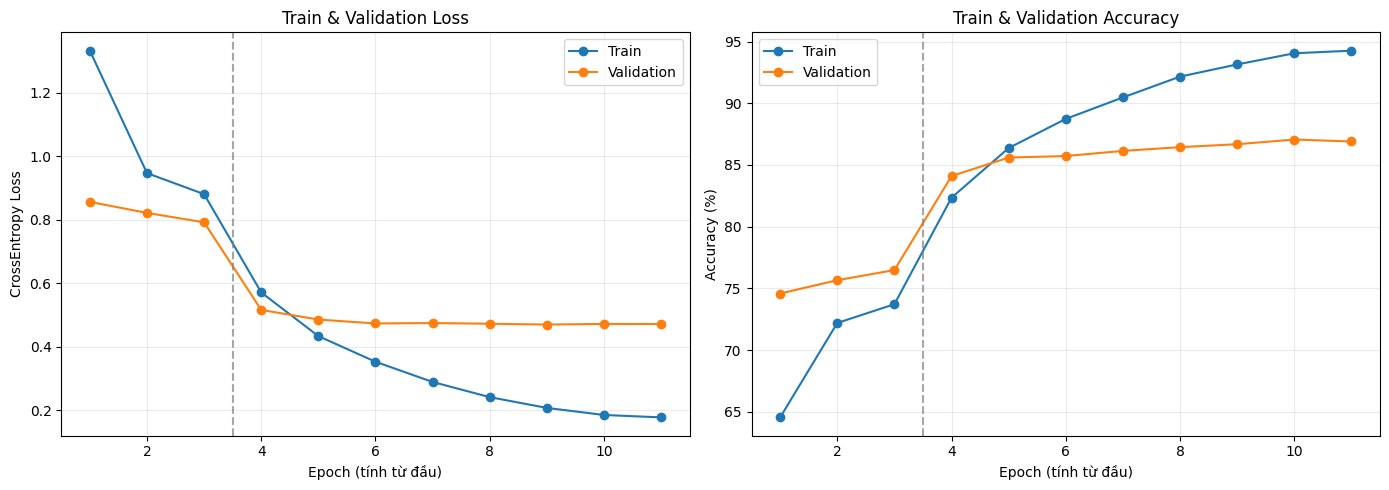

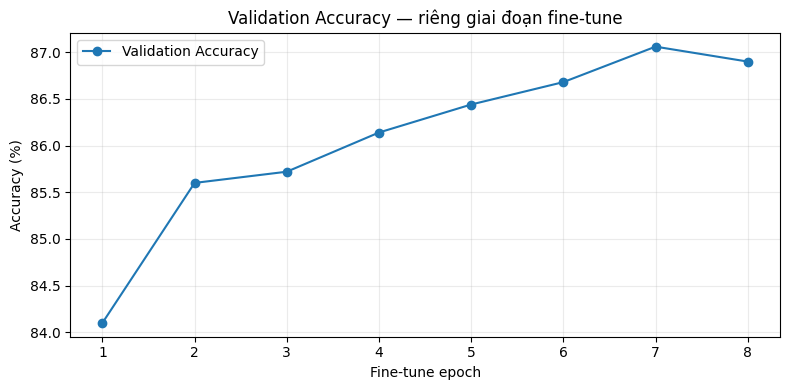

FINAL VALIDATION (BEST ACC):   0%|          | 0/313 [00:00<?, ?it/s]

BEST FINETUNE epoch: 7 | Validation Accuracy: 87.06% | Validation Loss: 0.4722
BEST LOSS checkpoint: /kaggle/working/lab7_swin_cifar100_results/best_finetune_by_loss.pth


In [21]:
# 7.10 — VẼ LEARNING CURVES VÀ LƯU PNG
hist=pd.DataFrame(history)
assert len(hist)==HEAD_EPOCHS+FINE_TUNE_EPOCHS
fig,axs=plt.subplots(1,2,figsize=(14,5))
for key,label in [('train_loss','Train'),('val_loss','Validation')]:
    axs[0].plot(hist.global_epoch,hist[key],marker='o',label=label)
for key,label in [('train_acc','Train'),('val_acc','Validation')]:
    axs[1].plot(hist.global_epoch,hist[key]*100,marker='o',label=label)
for a in axs:
    a.axvline(HEAD_EPOCHS+0.5,linestyle='--',color='gray',alpha=.7)
    a.set_xlabel('Epoch (tính từ đầu)');a.grid(alpha=.25);a.legend()
axs[0].set_title('Train & Validation Loss');axs[0].set_ylabel('CrossEntropy Loss')
axs[1].set_title('Train & Validation Accuracy');axs[1].set_ylabel('Accuracy (%)')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'learning_curves.png',dpi=200);plt.show()

ft=hist[hist.phase=='finetune']
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(ft.epoch_in_phase,ft.val_acc*100,marker='o',label='Validation Accuracy')
ax.set_title('Validation Accuracy — riêng giai đoạn fine-tune')
ax.set_xlabel('Fine-tune epoch');ax.set_ylabel('Accuracy (%)');ax.grid(alpha=.25);ax.legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'finetune_validation_accuracy.png',dpi=200);plt.show()

best_path=OUTPUT_DIR/'best_finetune_by_acc.pth'
ckpt=torch.load(best_path,map_location='cpu',weights_only=True)
my_model.load_state_dict(ckpt['model_state_dict'])
my_model=my_model.to(DEVICE)
val_loss,val_acc=one_epoch(val_loader,None,'FINAL VALIDATION (BEST ACC)')
print('BEST FINETUNE epoch:',ckpt['epoch'],'| Validation Accuracy:',f'{val_acc:.2%}',
      '| Validation Loss:',f'{val_loss:.4f}')
print('BEST LOSS checkpoint:',str(OUTPUT_DIR/'best_finetune_by_loss.pth'))
summary={'dataset':'CIFAR-100','model':'Swin-T','pretrained':'ImageNet1K_V1',
         'train_size':len(train_ds),'validation_size':len(val_ds),'test_size':len(test_ds),
         'total_parameters':param_count(my_model),'head_parameters':param_count(my_model.head),
         'best_finetune_epoch_by_acc':int(ckpt['epoch']),
         'best_validation_accuracy':float(val_acc),'validation_loss_at_best_acc':float(val_loss),
         'best_finetune_validation_loss':float(checkpoint_info['finetune']['best_val_loss']),
         'test_used_for_selection':False}
with open(OUTPUT_DIR/'validation_summary.json','w',encoding='utf-8') as f:
    json.dump(summary,f,indent=2,ensure_ascii=False)


In [22]:
# 7.10 BỔ SUNG — XEM TRỌNG SỐ VÀ BIAS THỰC TẾ CỦA HEAD (BEST CHECKPOINT)
# Shape head.weight=(100,768), head.bias=(100,)
state=ckpt['model_state_dict']
W=state['head.weight'].detach().cpu().float().numpy()
bias=state['head.bias'].detach().cpu().float().numpy()
print('Weight shape:',W.shape,'| Bias shape:',bias.shape)
print('Weight 5x5 đầu tiên:\n',W[:5,:5]);print('Bias 10 lớp đầu:',bias[:10])
print('Weight mean/std/min/max:',W.mean(),W.std(),W.min(),W.max())
print('Bias mean/std/min/max:',bias.mean(),bias.std(),bias.min(),bias.max())
pd.DataFrame(W,index=class_names).to_csv(OUTPUT_DIR/'head_weights_100x768.csv',index_label='class')
pd.DataFrame({'class':class_names,'bias':bias}).to_csv(OUTPUT_DIR/'head_bias_100.csv',index=False)
# So sánh trọng số head từ best_head giai đoạn 1 và best_finetune
head_state=head_ckpt['model_state_dict']
for name in ('head.weight','head.bias'):
    delta=torch.linalg.vector_norm(state[name].float()-head_state[name].float()).item()
    print('L2 change after fine-tune',name,':',round(delta,6))


Weight shape: (100, 768) | Bias shape: (100,)
Weight 5x5 đầu tiên:
 [[-0.10918355 -0.11597036 -0.16104373  0.05052792 -0.03771073]
 [ 0.107573    0.0614944  -0.04916945  0.08884199  0.19626449]
 [ 0.05701707 -0.0081484   0.05126191 -0.20414369  0.09059737]
 [-0.00562774 -0.17575014 -0.02760342 -0.09944846  0.04548395]
 [-0.10940476 -0.156328   -0.02278702  0.11574994  0.04899073]]
Bias 10 lớp đầu: [-0.0075064  -0.03128769  0.00250071  0.02821003 -0.01436231 -0.02977285
 -0.02750319  0.04184281 -0.05229223 -0.01101001]
Weight mean/std/min/max: 0.0002826362 0.083676554 -0.36502534 0.36886683
Bias mean/std/min/max: -0.007000302 0.03244188 -0.10973982 0.07204804
L2 change after fine-tune head.weight : 3.159363
L2 change after fine-tune head.bias : 0.059999


In [23]:
# ## 7.11 Run the Assessment — TEST cuối cùng cho CIFAR-100
# Trong lab gốc, `run_assessment` là bộ chấm riêng cho bài trái cây. Ở đây dùng **TEST của CIFAR-100 (10.000 ảnh)** làm đánh giá độc lập sau khi lựa chọn checkpoint bằng Validation. **TEST không học, không cập nhật trọng số, không dùng để chọn tham số.** Mặc định `RUN_FINAL_TEST=True` để chạy một lần khi bạn đã chốt cấu hình này; nếu đang thử siêu tham số thì đặt thành `False`.

FINAL TEST:   0%|          | 0/625 [00:00<?, ?it/s]

TEST ACCURACY: 86.57% | TEST MACRO-F1: 0.8655


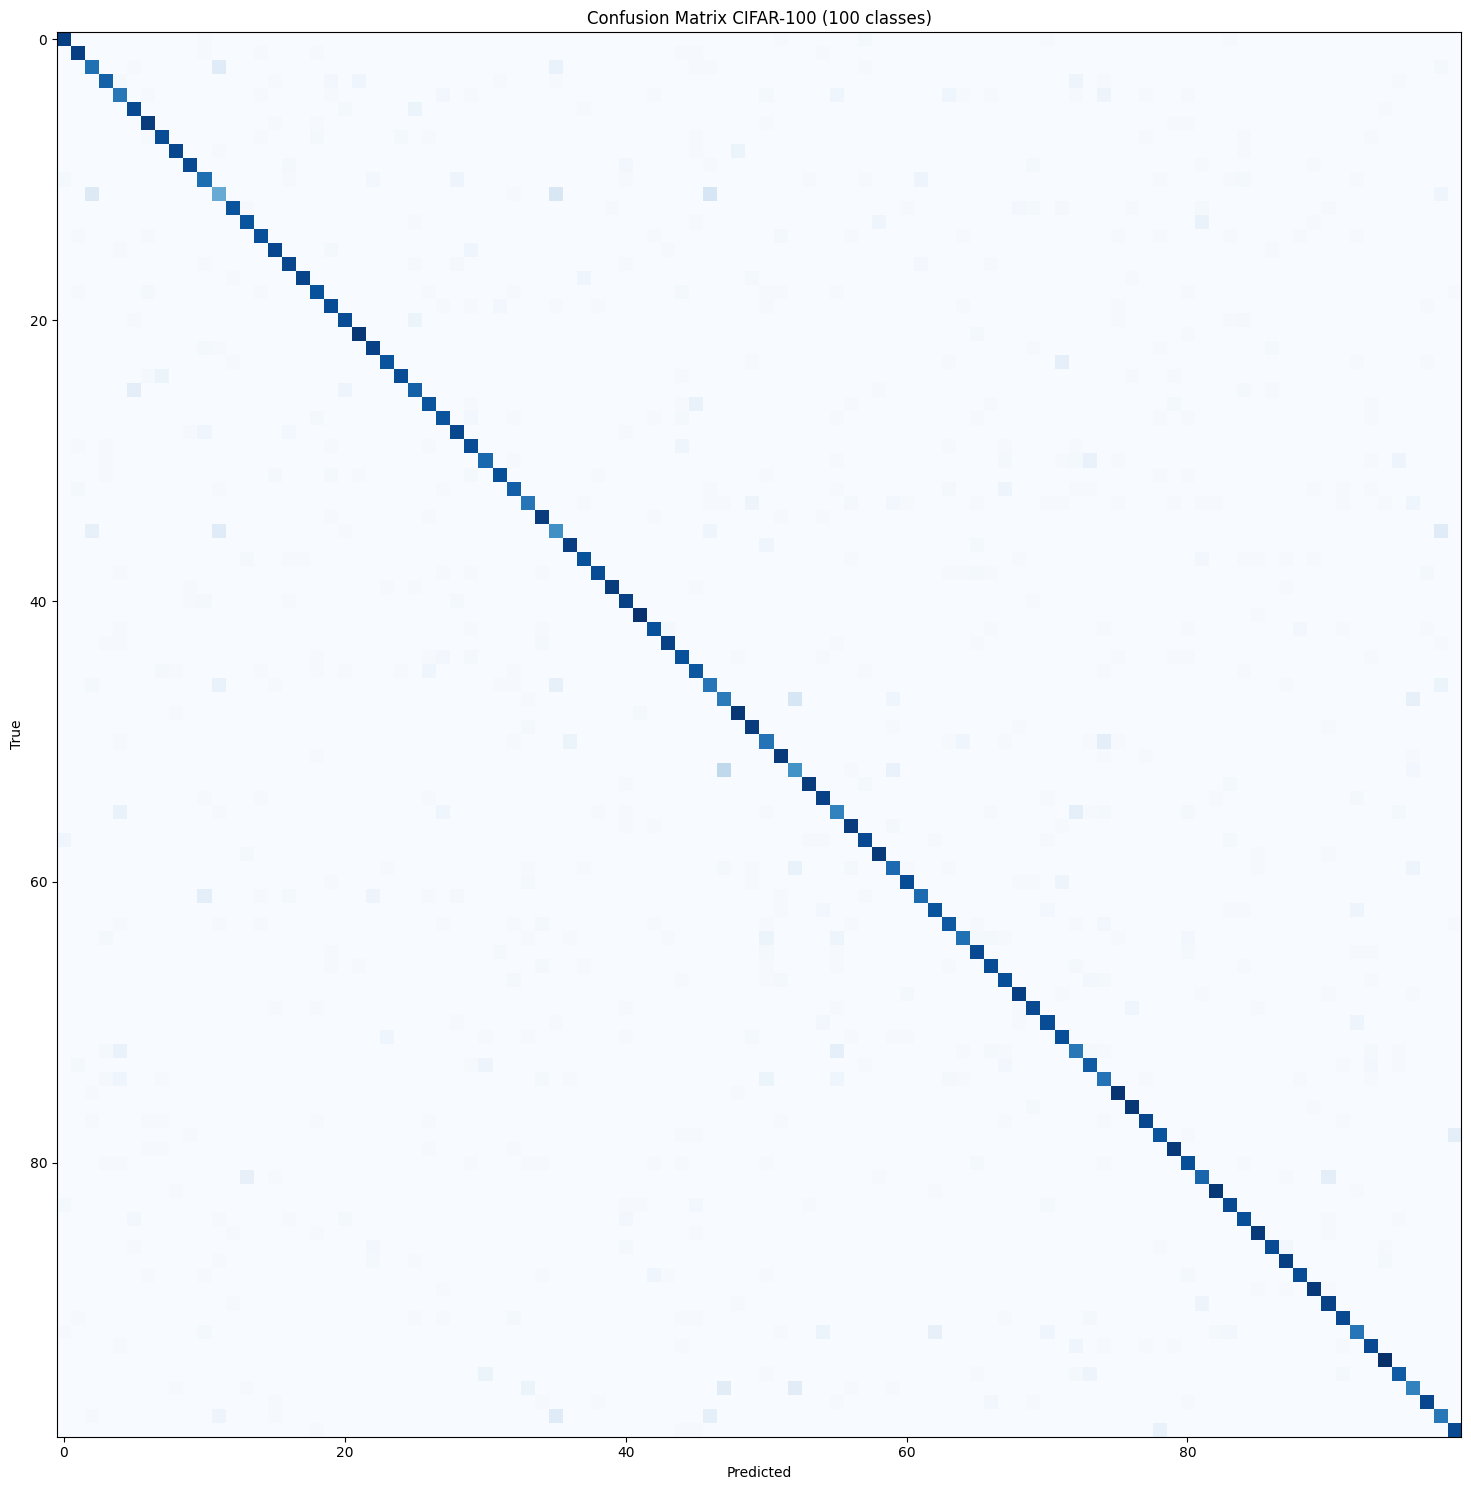

In [24]:
# 7.11 — TEST ĐỘC LẬP, CLASSIFICATION REPORT, CONFUSION MATRIX
if RUN_FINAL_TEST:
    # Đảm bảo test dùng model tốt nhất theo validation accuracy
    final_ckpt=torch.load(best_path,map_location='cpu',weights_only=True)
    my_model.load_state_dict(final_ckpt['model_state_dict'])
    my_model.eval()
    preds=[]; truths=[]
    with torch.inference_mode():
        for x,y in tqdm(test_loader,desc='FINAL TEST',mininterval=10):
            x=x.to(DEVICE,non_blocking=True)
            with torch.autocast(device_type='cuda',enabled=DEVICE.type=='cuda'):
                logits=my_model(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            truths.extend(y.numpy().tolist())
    test_acc=float(np.mean(np.asarray(preds)==np.asarray(truths)))
    test_f1=float(f1_score(truths,preds,average='macro'))
    print(f'TEST ACCURACY: {test_acc:.2%} | TEST MACRO-F1: {test_f1:.4f}')
    report=classification_report(truths,preds,target_names=class_names,output_dict=True,zero_division=0)
    pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR/'classification_report.csv')
    cm=confusion_matrix(truths,preds,labels=list(range(N_CLASSES)))
    pd.DataFrame(cm,index=class_names,columns=class_names).to_csv(OUTPUT_DIR/'confusion_matrix.csv')
    fig,ax=plt.subplots(figsize=(15,15))
    ax.imshow(cm,cmap='Blues')
    ax.set_title('Confusion Matrix CIFAR-100 (100 classes)')
    ax.set_xlabel('Predicted');ax.set_ylabel('True')
    plt.tight_layout();plt.savefig(OUTPUT_DIR/'confusion_matrix.png',dpi=200);plt.show()
    summary.update({'test_accuracy':test_acc,'test_macro_f1':test_f1,
                    'correct_test_images':int(np.sum(np.asarray(preds)==np.asarray(truths)))})
    with open(OUTPUT_DIR/'final_results.json','w',encoding='utf-8') as f:
        json.dump(summary,f,ensure_ascii=False,indent=2)
else:
    print('Đã bỏ qua TEST. Khi chốt cấu hình, đặt RUN_FINAL_TEST=True và chạy lại cell 7.11.')


In [25]:
# ## 7.12 (phần lưu báo cáo thay cho Certificate)
# Lab 7 gốc tạo chứng chỉ sau assessment; không áp dụng trên Kaggle. Cell dưới đóng gói **checkpoint, đồ thị, CSV weight/bias, history và kết quả** thành ZIP ở `/kaggle/working/`. Tải file ZIP từ bảng Output của Kaggle. Nếu ZIP quá lớn, tải từng kết quả hoặc dùng checkpoint riêng.

In [26]:
# LƯU THỐNG KÊ, CONFIG VÀ NÉN TẤT CẢ OUTPUTS
config={'seed':SEED,'num_classes':N_CLASSES,'image_size':IMAGE_SIZE,'batch_size':BATCH_SIZE,
        'head_epochs':HEAD_EPOCHS,'finetune_epochs':FINE_TUNE_EPOCHS,
        'head_lr':HEAD_LR,'backbone_lr':BACKBONE_LR,'finetune_head_lr':FINETUNE_HEAD_LR,
        'weight_decay':WEIGHT_DECAY,'run_final_test':RUN_FINAL_TEST,
        'selected_checkpoint':str(best_path),'optimizer':'AdamW','loss':'CrossEntropyLoss'}
with open(OUTPUT_DIR/'config.json','w',encoding='utf-8') as f:
    json.dump(config,f,ensure_ascii=False,indent=2)
pd.DataFrame(history).to_csv(OUTPUT_DIR/'training_history.csv',index=False)
zip_path=Path('/kaggle/working/lab7_swin_cifar100_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3) as z:
    for f in sorted(OUTPUT_DIR.rglob('*')):
        if f.is_file(): z.write(f,arcname=f.relative_to(OUTPUT_DIR.parent))
print('Đã lưu thư mục:',OUTPUT_DIR)
print('Đã tạo ZIP:',zip_path)
print('Các tệp:')
for f in sorted(OUTPUT_DIR.iterdir()): print('  ',f.name)


Đã lưu thư mục: /kaggle/working/lab7_swin_cifar100_results
Đã tạo ZIP: /kaggle/working/lab7_swin_cifar100_results.zip
Các tệp:
   best_finetune_by_acc.pth
   best_finetune_by_loss.pth
   best_head_by_acc.pth
   best_head_by_loss.pth
   classification_report.csv
   config.json
   confusion_matrix.csv
   confusion_matrix.png
   final_results.json
   finetune_validation_accuracy.png
   head_bias_100.csv
   head_weights_100x768.csv
   learning_curves.png
   split_indices.npz
   training_history.csv
   validation_summary.json
